## Exercise 2

we now want to use the CGLS-method (conjugate gradient least square method) to recover x, by minimizing $\| Kx - y^{\delta} \|_2$ through iterations over the 

**Krylov space**

$$
\mathcal{K}_k = span\{K^Ty,(K^T K)K^T y, ..., (K^T K)^k K^T y\}
$$

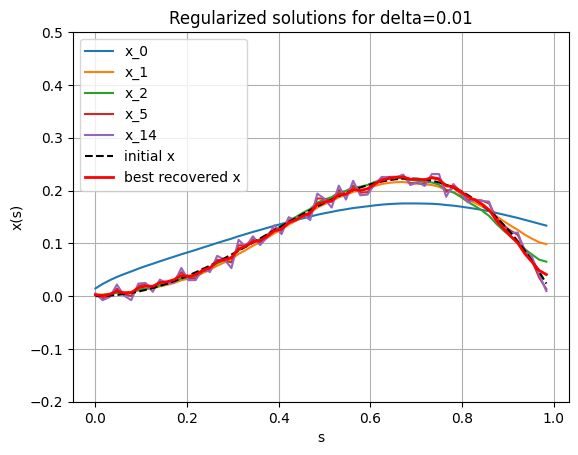

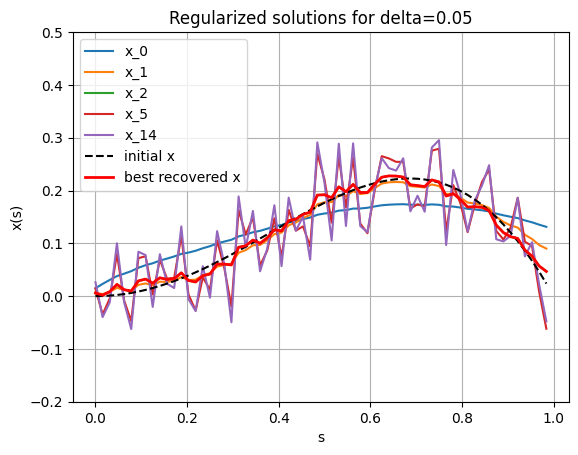

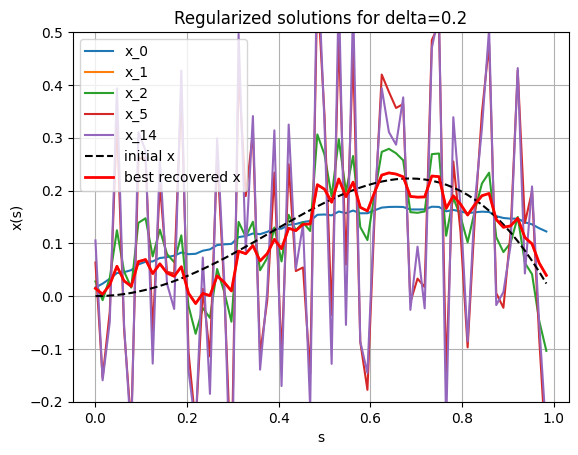


CGLS — best reconstruction for each noise level
   Noise   Best iteration    Min. rel. error
----------------------------------------------
      1%                4           0.030423
      5%                3           0.080511
     20%                2           0.215469


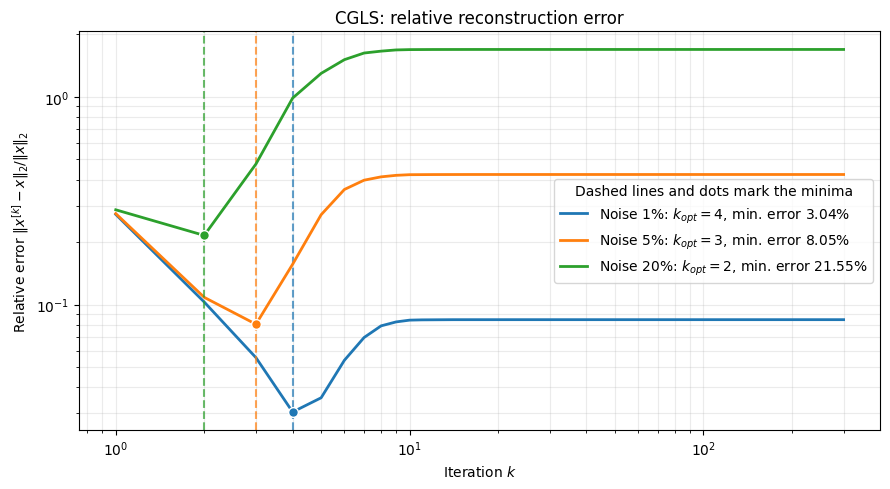

In [62]:
import numpy as np
import matplotlib.pyplot as plt

n = 64
x = lambda s: s**2 * np.cos(np.pi * s / 2)

s_grid = np.array([i/n for i in range(64)])
t_grid = s_grid + 0.5*1/n

x_grid = x(s_grid)

A = np.zeros((n,n))
for i,s in enumerate(s_grid):
    for j,t in enumerate(t_grid):
        if t-s >= 0:
            A[i,j] = 1 / np.sqrt(t-s) * 1/n     # 1/n comes from numerical integral, we have to consider the measure of our intervals!
        else:
            A[i,j] = 0

y = A @ x_grid

# CGLS algorithm
maxIter = 300
k_array = [1,2,3,6,15]

d_array = np.array([0.01,0.05,0.2])

relativeError = np.zeros((len(d_array),maxIter))
minError_ind = np.full(len(d_array),maxIter)
minError = np.full(len(d_array),np.linalg.norm(x_grid))      # initial value

x_delta = np.zeros(n)


for i,percent in enumerate(d_array):
    # noise
    np.random.seed(42)
    d = np.random.randn(n)
    d = d / np.linalg.norm(d) * percent * np.linalg.norm(y)
    y_delta = y + d

    #for k=0
    xk = np.zeros(n)    # array
    rk = y_delta        # array
    sk = A.T @ rk       # array
    dk = sk             # array

    for k in range(maxIter):
        sk_old = sk

        ak_new = np.linalg.norm(sk_old)**2 / np.linalg.norm( A @ dk)**2   # scalar
        
        xk = xk + ak_new * dk       # array
        rk = rk - ak_new * A @ dk   
        sk = A.T @ rk
        bk = np.linalg.norm(sk)**2 / np.linalg.norm(sk_old)**2      # scalar

        dk = sk + bk * dk

        sk_old = sk
        relativeError[i,k] = np.linalg.norm( xk - x_grid ) / np.linalg.norm( x_grid)
        if relativeError[i,k] < minError[i]:
            minError[i] = relativeError[i,k]
            minError_ind[i] = k
            x_delta = xk

        if k+1 in k_array: 
            plt.plot(s_grid,xk,label=f"x_{k}")

            # ax_error.loglog( np.linspace(0, maxIter, maxIter), relativeError[i], label=f"delta={percent}, {k}-th iter")
            # plt.plot( s_grid, xk, label=f"x_{k}", linestyle="--")

    plt.plot(s_grid,x_grid,label="initial x",color="black",linestyle="--")
    plt.plot(s_grid,x_delta,label="best recovered x",color="red",lw=2)
    plt.xlabel("s")
    plt.ylabel("x(s)")
    plt.legend()
    plt.title(f"Regularized solutions for delta={percent}")
    plt.grid(True)
    plt.ylim(-0.2,0.5)
    
    plt.show() 

# region PLOT
fig, ax = plt.subplots(figsize=(9, 5))
iterations = np.arange(1, maxIter + 1)

print("\nCGLS — best reconstruction for each noise level")
print(f"{'Noise':>8} {'Best iteration':>16} {'Min. rel. error':>18}")
print("-" * 46)

for i, percent in enumerate(d_array):
    best_idx = np.argmin(relativeError[i])
    k_opt = best_idx + 1
    error_opt = relativeError[i, best_idx]

    line, = ax.loglog(iterations,relativeError[i],lw=2,label=(f"Noise {percent:.0%}: "f"$k_{{opt}}={k_opt}$, min. error {error_opt:.2%}"))
    color = line.get_color()

    ax.axvline(k_opt, color=color, linestyle="--", alpha=0.7)
    ax.plot(k_opt, error_opt,marker="o", color=color, markersize=7,markeredgecolor="white", zorder=5)

    print(f"{percent:8.0%} {k_opt:16d} {error_opt:18.6f}")

ax.set_xlabel("Iteration $k$")
ax.set_ylabel(r"Relative error $\|x^{[k]}-x\|_2/\|x\|_2$")
ax.set_title("CGLS: relative reconstruction error")
ax.grid(True, which="both", alpha=0.25)
ax.legend(title="Dashed lines and dots mark the minima")
fig.tight_layout()
plt.show()

# endregion

## Exercise 2b

$cond(K) = \kappa(K) = \|K\| \cdot \|K^{-1}\| = \frac{\sigma_{max}(K)}{\sigma_{min}(K)}$ ($\sigma$ means singular values)
___
***Remark***: 
*Relation to eigenvalues:* $\sigma_i(A) = \sqrt{\lambda_i A^T A}$

because $A x_j = \sigma_j y_j$ and $A^T y_j = \sigma_j x_j \quad \Rightarrow \quad (A^TA) x_j = \sigma_j A^T y_j = \sigma_j^2 x_j$

so if $\sigma_j$ is a singular value of A, then $\sigma_j^2$ is an eigenvalue of $A^TA$
___
...the condition number of a matrix K measures how **sensitive the solution $x$** of a linear system $Ax = b$ is to **small changes** or round-off errors in the **input data $b$**

if $\kappa(K) \approx 1 \rightarrow$ well-conditioned

if $\kappa(K) \gg 1 \rightarrow$ ill-conditioned

if $\kappa(K) = \infty \rightarrow$ K is singular (non invertible)

In [63]:
Ainv = np.linalg.inv(A)
conditionA = np.linalg.norm(A,ord=2) * np.linalg.norm(Ainv,ord=2)

singularvalues = np.linalg.svd(A,compute_uv=False)
kappaA = singularvalues[0] / singularvalues[-1]

print(conditionA)
print(kappaA)


11.907627123323644
11.907627123323646


we need a lot of noise for semi-convergence, since it is pretty well-conditioned

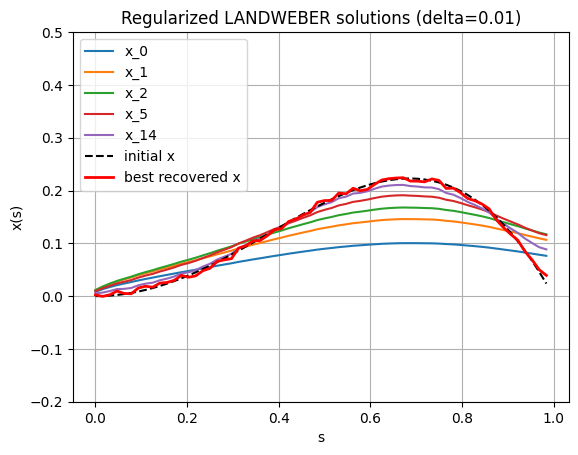

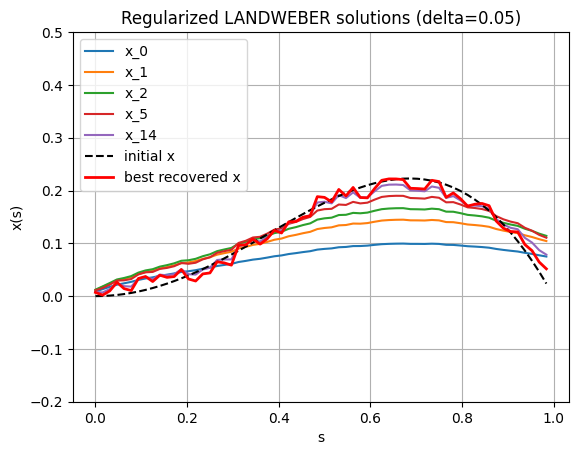

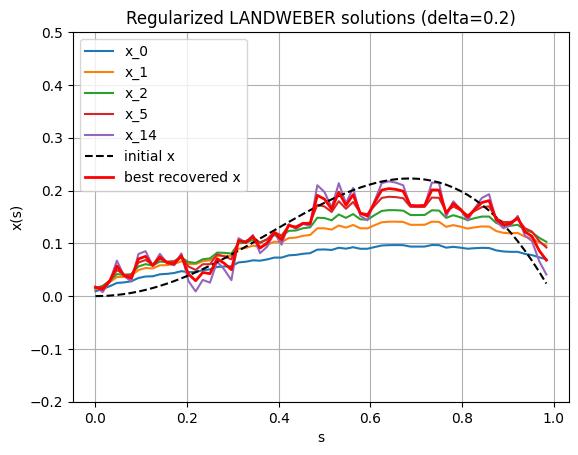


Landweber — best reconstruction for each noise level
   Noise   Best iteration    Min. rel. error
----------------------------------------------
      1%               60           0.031465
      5%               26           0.092364
     20%               10           0.218651


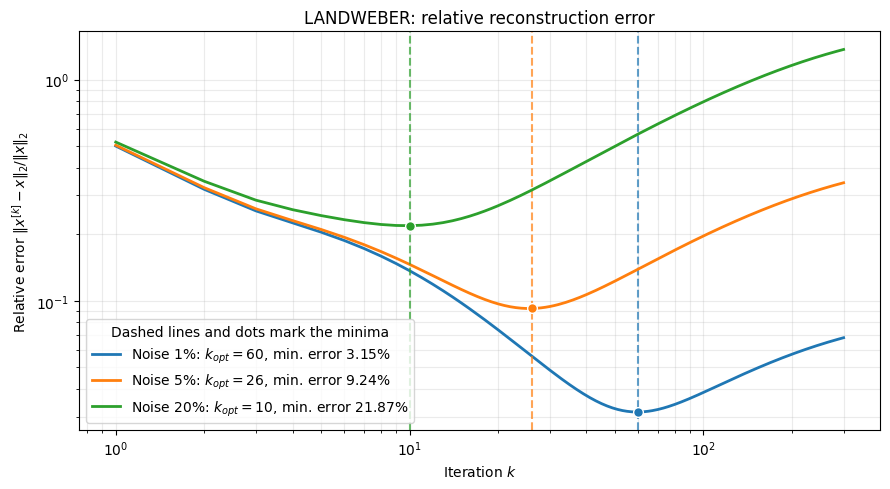


Comparison: CGLS vs. Landweber
  Noise |           CGLS            |         Landweber        
        |    k_opt       Min. error |    k_opt       Min. error
-----------------------------------------------------------------
     1% |        4            3.04% |       60            3.15%
     5% |        3            8.05% |       26            9.24%
    20% |        2           21.55% |       10           21.87%


In [64]:
# 3c) LANDWEBER method

# LANDWEBER algorithm
maxIter = 300
k_array = [1,2,3,6,15]

d_array = np.array([0.01,0.05,0.2])

relativeError_LW = np.zeros((len(d_array),maxIter))
minError_ind_LW = np.full(len(d_array),maxIter)
minError_LW = np.full(len(d_array),np.linalg.norm(x_grid))      # initial value

x_delta = np.zeros(n)
omega = 1.5 / np.linalg.norm(A)**2

for i,percent in enumerate(d_array):
    # noise
    np.random.seed(42)
    d = np.random.randn(n)
    d = d / np.linalg.norm(d) * percent * np.linalg.norm(y)
    y_delta = y + d

    #for k=0
    xk = np.zeros(n)

    
    for k in range(maxIter):
        xk = xk + omega * A.T @ (y_delta - A@xk)
        relativeError_LW[i,k] = np.linalg.norm( xk - x_grid ) / np.linalg.norm( x_grid)

        if relativeError_LW[i,k] < minError_LW[i]:
            minError_LW[i] = relativeError_LW[i,k]
            minError_ind_LW[i] = k
            x_delta = xk

        if k+1 in k_array: 
            plt.plot(s_grid,xk,label=f"x_{k}")

    plt.plot(s_grid,x_grid,label="initial x",color="black",linestyle="--")
    plt.plot(s_grid,x_delta,label="best recovered x",color="red",lw=2)
    plt.xlabel("s")
    plt.ylabel("x(s)")
    plt.legend()
    plt.title(f"Regularized LANDWEBER solutions (delta={percent})")
    plt.grid(True)
    plt.ylim(-0.2,0.5)

    plt.show() 

# region PLOT
fig_LW, ax_LW = plt.subplots(figsize=(9, 5))
iterations = np.arange(1, maxIter + 1)

print("\nLandweber — best reconstruction for each noise level")
print(f"{'Noise':>8} {'Best iteration':>16} {'Min. rel. error':>18}")
print("-" * 46)

for i, percent in enumerate(d_array):
    best_idx = np.argmin(relativeError_LW[i])
    k_opt = best_idx + 1
    error_opt = relativeError_LW[i, best_idx]

    line, = ax_LW.loglog(iterations,relativeError_LW[i],lw=2,label=(f"Noise {percent:.0%}: "f"$k_{{opt}}={k_opt}$, min. error {error_opt:.2%}"))
    color = line.get_color()

    ax_LW.axvline(k_opt, color=color, linestyle="--", alpha=0.7)
    ax_LW.plot(k_opt, error_opt,marker="o", color=color, markersize=7,markeredgecolor="white", zorder=5)

    print(f"{percent:8.0%} {k_opt:16d} {error_opt:18.6f}")

ax_LW.set_xlabel("Iteration $k$")
ax_LW.set_ylabel(r"Relative error $\|x^{[k]}-x\|_2/\|x\|_2$")
ax_LW.set_title("LANDWEBER: relative reconstruction error")
ax_LW.grid(True, which="both", alpha=0.25)
ax_LW.legend(title="Dashed lines and dots mark the minima")
fig_LW.tight_layout()
plt.show()


print("\nComparison: CGLS vs. Landweber")
print(
    f"{'Noise':>7} | {'CGLS':^25} | {'Landweber':^25}"
)
print(
    f"{'':7} | {'k_opt':>8} {'Min. error':>16} | "
    f"{'k_opt':>8} {'Min. error':>16}"
)
print("-" * 65)

for i, percent in enumerate(d_array):
    idx_cgls = np.nanargmin(relativeError[i])
    idx_lw = np.nanargmin(relativeError_LW[i])

    print(
        f"{percent:7.0%} | "
        f"{idx_cgls + 1:8d} {relativeError[i, idx_cgls]:16.2%} | "
        f"{idx_lw + 1:8d} {relativeError_LW[i, idx_lw]:16.2%}"
    )
# endregion


landweber needs more iterations and is slightly more imprecise

LANDWEBER: 
- minITERATION 277
- RELATIVE ERROR 0.25141107366123644
CGLS: 
- minITERATION 418
- RELATIVE ERROR 0.08068983544838508


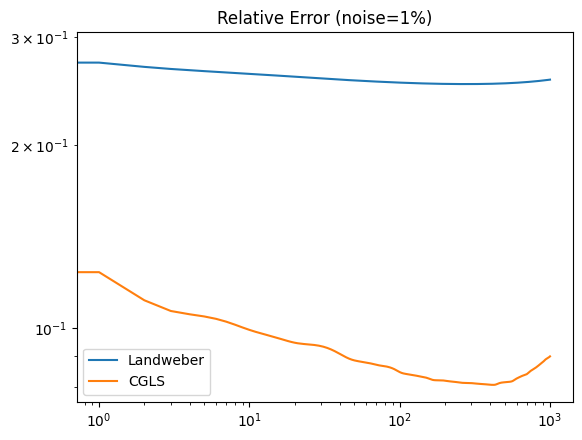

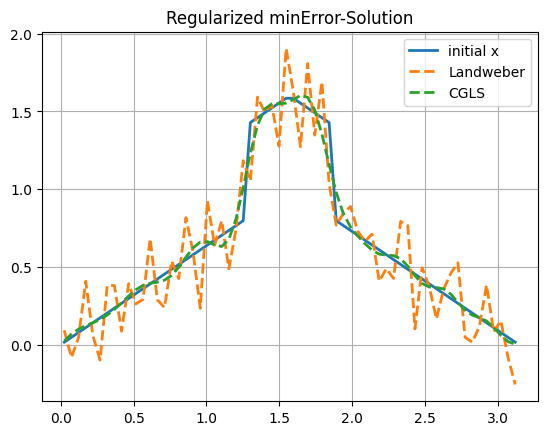

In [65]:
# Exercise 3d) Heat Problem with CGLS vs Landweber

# ---> copied from file w8_ex2_landweber.ipynb
import numpy as np
from scipy.fft import dst, idst
from matplotlib import pyplot as plt

def heat_forward(x, T):
    """Apply K on the midpoint grid s_i = (i-1/2)*pi/n."""
    j = np.arange(1,len(x)+1)
    c = dst(x, type=2, norm='ortho') # sine coefficients
    return idst(np.exp(-T * j**2) * c, type=2, norm='ortho')

#Computing the timesteps
T = 0.01
n = 64
h = np.pi/n

#Initializing and constructing A
H = np.zeros((n,n))

for i in range(n):
    x = np.zeros(n)
    x[i] = 1
    H[:,i] = heat_forward(x, T)

    #Defining the function x(s) and applying the discrete operator to obtain y
s = (np.arange(1,n+1) - 1/2) *h

x = lambda s: np.minimum(s, np.pi - s) / (np.pi / 2) + 0.6 * (np.abs(s - np.pi / 2) < 0.3)
x_vec = np.zeros(n)
x_vec[:] = x(s)
Kx = heat_forward(x_vec, T)

#Adding noise to y
np.random.seed(42)
d = np.random.randn(n)
d = d / np.linalg.norm(d) * 0.01 * np.linalg.norm(Kx)
y_delta = Kx + d

k_top = 1000        #amount of iterations

# --- LANDWEBER ITERATION ---
H_norm2 = np.linalg.norm(H,ord=2)
omega = 1/ H_norm2 **2

relativeError_LW = np.zeros(k_top)
xk_LW = np.zeros(n)
x_minError_LW = np.zeros(n)
minError_LW = 1000

for i in range(k_top):   
    xk = xk + omega * H.T @ (y_delta - H@xk)
    relativeError_LW[i] = np.linalg.norm(xk - x_vec)/np.linalg.norm(x_vec)

    if relativeError_LW[i] < minError_LW:
        minError_index_LW = i
        minError_LW = relativeError_LW[i]
        x_minError_LW = xk


# --- CGLS ---
relativeError_CGLS = np.zeros(k_top)
xk_CGLS = np.zeros(n)
x_minError_CGLS = np.zeros(n)
minError_CGLS = 1000

xk = np.zeros(n)
rk = y_delta
sk_old = H.T @ rk
dk = sk_old

for k in range(k_top):
    ak = np.linalg.norm(sk_old)**2 / np.linalg.norm(H @ dk)**2
    xk = xk + ak * dk
    rk = rk - ak * H @ dk
    sk_new = H.T @ rk
    bk = np.linalg.norm(sk_new) / np.linalg.norm(sk_old)
    dk = sk_new + bk * dk

    sk_old = sk_new 
    
    relativeError_CGLS[k] = np.linalg.norm(xk - x_vec)/np.linalg.norm(x_vec)
    
    if relativeError_CGLS[k] < minError_CGLS:
        minError_index_CGLS = k
        minError_CGLS = relativeError_CGLS[k]
        x_minError_CGLS = xk


print(f"LANDWEBER: \n- minITERATION {minError_index_LW}")
print(f"- RELATIVE ERROR {minError_LW}")

print(f"CGLS: \n- minITERATION {minError_index_CGLS}")
print(f"- RELATIVE ERROR {minError_CGLS}")

plt.loglog(relativeError_LW,label="Landweber")
plt.loglog(relativeError_CGLS, label="CGLS")
plt.title("Relative Error (noise=1%)")
plt.legend()
plt.show()

plt.plot(s,x_vec,label="initial x",lw=2)
plt.plot(s,x_minError_LW,label="Landweber",lw=2,linestyle="--")
plt.plot(s,x_minError_CGLS,label="CGLS",lw=2,linestyle="--")
plt.legend()
plt.title("Regularized minError-Solution")
plt.grid()
plt.show()


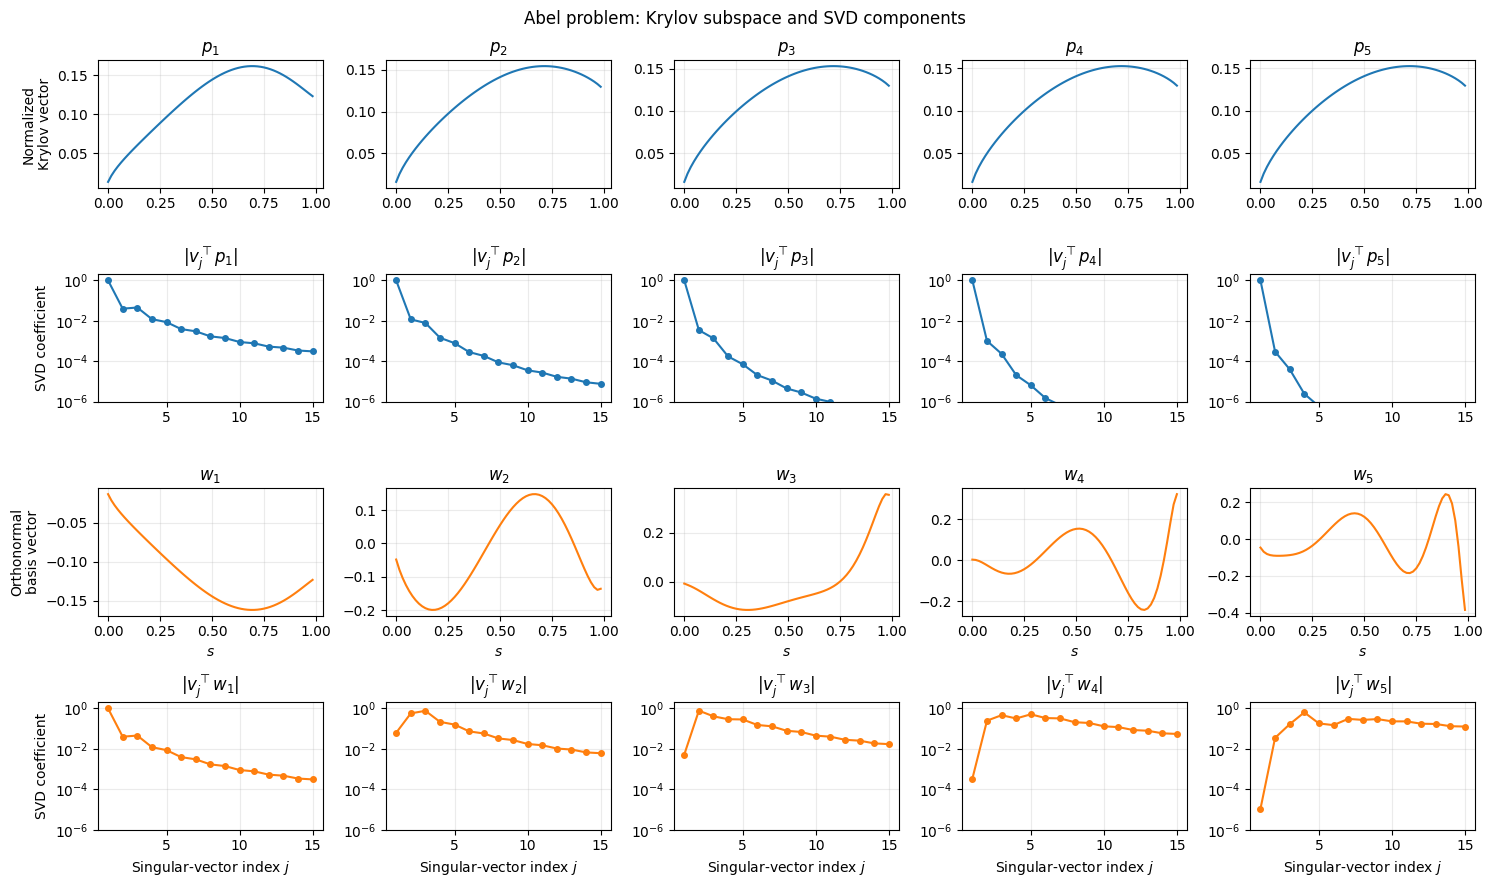

In [ ]:
# Exercise 3e) Krylov vectors and their SVD coefficients
# A must be the Abel matrix, not the Heat matrix!

y_abel = A @ x_grid       # noise-free data for this analysis
m = 5

U, sigma, Vt = np.linalg.svd(A, full_matrices=False)
V = Vt.T

# Normalized Krylov vectors:
# p_i proportional to (A.T @ A)^(i-1) @ A.T @ y
P = np.zeros((A.shape[1], m))       # first m vectors
p = A.T @ y_abel

for i in range(m):
    p = p / np.linalg.norm(p)
    P[:, i] = p
    p = A.T @ (A @ p)

# Orthonormal basis of the same Krylov subspace
W, _ = np.linalg.qr(P, mode="reduced")

# Expansion coefficients in the right singular-vector basis
coeff_P = np.abs(V.T @ P)
coeff_W = np.abs(V.T @ W)

fig, axes = plt.subplots(4, m, figsize=(15, 9))

j = np.arange(1, len(sigma) + 1)
j_show = min(15, len(sigma))
floor = 1e-16

for i in range(m):
    axes[0, i].plot(s_grid, P[:, i], color="tab:blue")
    axes[0, i].set_title(fr"$p_{i + 1}$")

    axes[1, i].semilogy(
        j[:j_show],
        np.maximum(coeff_P[:j_show, i], floor),
        "o-", color="tab:blue", markersize=4
    )
    axes[1, i].set_title(fr"$|v_j^\top p_{i + 1}|$")
    axes[1, i].set_ylim(1e-6, 2)

    axes[2, i].plot(s_grid, W[:, i], color="tab:orange")
    axes[2, i].set_title(fr"$w_{i + 1}$")
    axes[2, i].set_xlabel("$s$")

    axes[3, i].semilogy(
        j[:j_show],
        np.maximum(coeff_W[:j_show, i], floor),
        "o-", color="tab:orange", markersize=4
    )
    axes[3, i].set_title(fr"$|v_j^\top w_{i + 1}|$")
    axes[3, i].set_ylim(1e-6, 2)
    axes[3, i].set_xlabel("Singular-vector index $j$")

    for row in range(4):
        axes[row, i].grid(True, alpha=0.25)

axes[0, 0].set_ylabel("Normalized\nKrylov vector")
axes[1, 0].set_ylabel("SVD coefficient")
axes[2, 0].set_ylabel("Orthonormal\nbasis vector")
axes[3, 0].set_ylabel("SVD coefficient")

fig.suptitle("Abel problem: Krylov subspace and SVD components")
fig.tight_layout()
plt.show()